# Métricas do Dashboard 2 (teste antes do app)

Antes de levar as métricas para o `app.py`, os cálculos e plots prévios são testados aqui, sobre o dataset tratado (`data/clean/dataset.csv`).

**Variáveis selecionadas:** `sobreviveu` (variável de interesse), `age`, `fare` e as categóricas `sex`, `class` e `embark_town` (para agrupar).

**Widgets do Dashboard 2:** os filtros de intervalo da sidebar (os mesmos do Dashboard 1), um seletor "Agrupar por" (sexo, classe ou porto de embarque) e o clique numa barra do gráfico.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RAIZ = Path("..") if Path("../data").exists() else Path(".")
df = pd.read_csv(RAIZ / "data" / "clean" / "dataset.csv")
df["sobreviveu_num"] = df["sobreviveu"].eq("Sobreviveu")
df.shape

(782, 17)

## Métricas propostas

In [2]:
passageiros = len(df)                         # contagem
taxa_sobrevivencia = df["sobreviveu_num"].mean()  # proporção
idade_media = df["age"].mean()                # média
tarifa_mediana = df["fare"].median()          # mediana (fare é muito assimétrica, ver EDA)

print(f"Passageiros: {passageiros}")
print(f"Taxa de sobrevivência: {taxa_sobrevivencia:.1%}")
print(f"Idade média: {idade_media:.1f} anos")
print(f"Tarifa mediana: £ {tarifa_mediana:.2f} (média £ {df['fare'].mean():.2f})")

Passageiros: 782
Taxa de sobrevivência: 41.0%
Idade média: 29.8 anos
Tarifa mediana: £ 15.88 (média £ 34.60)


## Agrupando 1 variável: taxa de sobrevivência por grupo

In [3]:
for grupo in ["sex", "class", "embark_town"]:
    tabela = df.groupby(grupo)["sobreviveu_num"].agg(passageiros="size", taxa="mean")
    tabela["diferenca_pp"] = (tabela["taxa"] - taxa_sobrevivencia) * 100  # variação vs. geral
    print(tabela.round(3))
    print()

        passageiros   taxa  diferenca_pp
sex                                     
female          291  0.739        32.835
male            491  0.216       -19.460

        passageiros   taxa  diferenca_pp
class                                   
First           212  0.627        21.687
Second          165  0.509         9.860
Third           405  0.257       -15.370

             passageiros   taxa  diferenca_pp
embark_town                                  
Cherbourg            155  0.581        17.016
Queenstown            59  0.339        -7.150
Southampton          568  0.371        -3.901



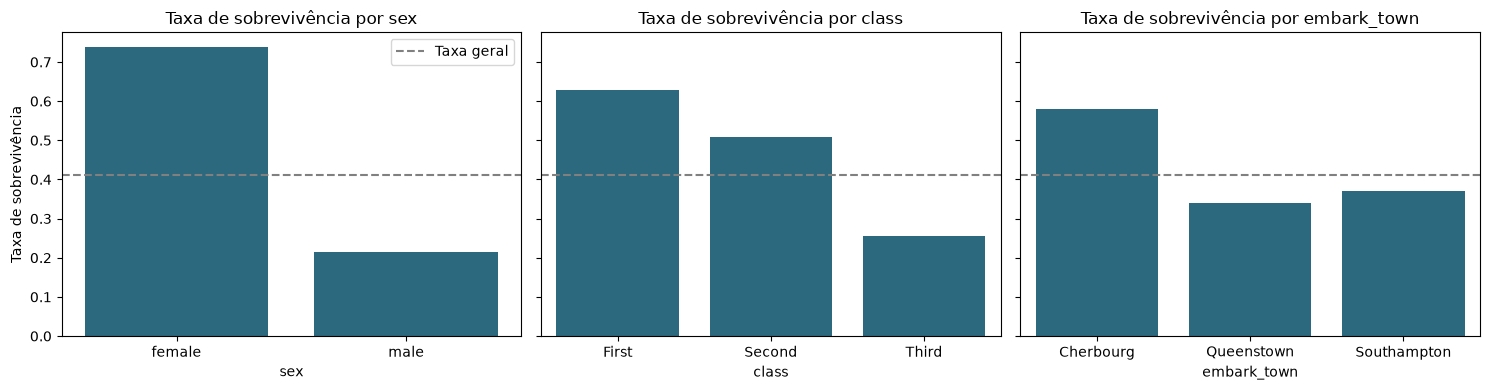

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, grupo in zip(axes, ["sex", "class", "embark_town"]):
    taxa = df.groupby(grupo)["sobreviveu_num"].mean()
    sns.barplot(x=taxa.index, y=taxa.values, color="#1f6f8b", ax=ax)
    ax.axhline(taxa_sobrevivencia, color="gray", linestyle="--", label="Taxa geral")
    ax.set_title(f"Taxa de sobrevivência por {grupo}")
    ax.set_xlabel(grupo)
    ax.set_ylabel("Taxa de sobrevivência")
axes[0].legend()
plt.tight_layout()
plt.show()